# Questão 2 — Extração de argumentos de sentenças: demonstração

Python 3.14, `pymupdf`, `numpy`, `scipy`, `pydantic`, `matplotlib` (versões em `requirements.txt`). O código da solução está em `q2.py`; este caderno só executa as demonstrações. Rodar com *Restart & Run All*.

As sentenças são sintéticas, geradas em PDF com gabarito (seeds fixas). O LLM é simulado: responde às mesmas requisições que o cliente real recebe e erra com taxas definidas em `PerfilSimulado`. Essas taxas não medem nenhum modelo; servem para exercitar cada controle. Os números de qualidade deste caderno mostram que o mecanismo funciona, não a qualidade de um modelo real, que se mede no conjunto de referência anotado (seção 5 do `questao2.md`).

In [1]:
import json
import sys
from dataclasses import replace

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pydantic
import pymupdf
import scipy

from q2 import *

print(f"Python {sys.version.split()[0]} | pymupdf {pymupdf.__version__} | numpy {np.__version__} | scipy {scipy.__version__} | pydantic {pydantic.__version__}")
VERSAO_ATIVA, PARTES_VERSAO = versao_extracao("perfil=ativa")
print("versão de extração:", VERSAO_ATIVA, json.dumps(PARTES_VERSAO, ensure_ascii=False))

Python 3.14.6 | pymupdf 1.28.2 | numpy 2.5.4 | scipy 1.18.1 | pydantic 2.14.1
versão de extração: ext_c28d8ed1f5 {"prompts": {"mapa": "f8585c88501e", "extrator": "c5eeb665f7a9", "verificador": "539ecbc8c96c"}, "modelos": ["claude-haiku-5-5", "claude-sonnet-5-5", "claude-haiku-5-5"], "schema": "2.1.0", "codigo": "0d94d89126bd", "embeddings": "BAAI/bge-m3@5617a9f", "extra": "perfil=ativa"}


## 1. Uma sentença, do PDF aos parágrafos numerados

*Afirmação:* Antes de qualquer LLM, o código divide a sentença em parágrafos `§1…§n` com página e offsets, separa relatório, fundamentação e dispositivo, marca os tópicos do juiz e marca as citações (recuo, aspas, marcador, formato de ementa). Citação depois de "adoto como razões de decidir" é marcada como adotada.

In [2]:
pdf, gab = gerar_sentenca(7, area="negativacao", juizado=False, titulos=True, preliminar=True, preexistente=False,
                          relationem=True, obiter=True, relato=True, ocr=True)
sent = ler_pdf(gab.sentenca_id, pdf)
marcar_citacoes(sent)
regex = fronteiras_regex(sent)
segmentar(sent, {k: regex[k] for k in ("fundamentacao", "dispositivo")})
print(f"{gab.sentenca_id}: {pymupdf.open(stream=pdf).page_count} páginas, {len(sent.paragrafos)} parágrafos, texto_hash {sent.texto_hash}")
print(f"fronteiras pela regex: fundamentação §{regex['fundamentacao']}, dispositivo §{regex['dispositivo']} | gabarito: {gab.fronteiras}\n")
for p in sent.paragrafos:
    marca = "citação adotada" if p.adotado else ("citação" if p.e_citacao else ("título" if p.titulo else ""))
    print(f"§{p.indice:<3} pág.{p.pagina} {p.secao:<14} {p.topico[:26]:<27} {marca:<16} {p.texto[:70]}")
assert {"fundamentacao": regex["fundamentacao"], "dispositivo": regex["dispositivo"]} == gab.fronteiras
adotados = [p.indice for p in sent.paragrafos if p.adotado]
assert adotados == [a.paragrafo for a in gab.argumentos if a.id == "dm"], "o bloco per relationem é o argumento de dano moral"
print("\ntópicos (unidade de extração):", [(t["id"], t["titulo"], t["paragrafos"]) for t in topicos(sent)])

sent_0007: 2 páginas, 31 parágrafos, texto_hash 41e1dfd897008c27
fronteiras pela regex: fundamentação §13, dispositivo §27 | gabarito: {'fundamentacao': 13, 'dispositivo': 27}

§1   pág.1 cabecalho                                                   PODER JUDICIÁRIO
§2   pág.1 cabecalho                                                   TRIBUNAL DE JUSTIÇA DO ESTADO DE SÃO PAULO
§3   pág.1 cabecalho                                                   1ª Vara Cível da Comarca de Ribeirão Preto
§4   pág.1 cabecalho                                                   Processo nº 2171979-40.2024.8.26.0565
§5   pág.1 cabecalho                                                   Requerente: Helena Rodrigues - Requerido: Banco Vértice S.A.
§6   pág.1 cabecalho                                                   SENTENÇA
§7   pág.1 relatorio                                                   Vistos.
§8   pág.1 relatorio                                                   RELATÓRIO
§9   pág.1 relatorio      

## 2. Saída estruturada

*Afirmação:* O modelo devolve uma ferramenta obrigatória com JSON Schema estrito (gerado do Pydantic): enums fechados, nenhum campo fora do schema. Limites de tamanho não vão na decodificação; o Pydantic confere na volta. Prompts e schema têm hash, que entra na versão.

In [3]:
schema = schema_para_api(RespostaExtrator)
arg_schema = schema["$defs"]["ArgumentoCandidato"]
print("campos obrigatórios do candidato:", arg_schema["required"])
print("tipos:", schema["$defs"]["Tipo"]["enum"])
assert arg_schema["additionalProperties"] is False
print("hash dos prompts:", versao_prompts())
try:
    ArgumentoCandidato(titulo="x", resumo="y", tipo="jurisprudencia", por_que_papel="z", papel="ratio_decidendi", pedidos=["P1"], conclusao="acolhe",
                       favorece="autor", paragrafos=[3], citacao_literal="trecho qualquer da sentença copiado", normas=[], precedentes=[])
except pydantic.ValidationError as erro:
    print("tipo fora do enum é rejeitado:", erro.errors()[0]["msg"][:80])

campos obrigatórios do candidato: ['titulo', 'resumo', 'tipo', 'por_que_papel', 'papel', 'pedidos', 'conclusao', 'favorece', 'paragrafos', 'citacao_literal', 'normas', 'precedentes']
tipos: ['preliminar_processual', 'prejudicial_merito', 'merito_fato', 'merito_direito', 'onus_prova', 'quantificacao', 'outro']
hash dos prompts: {'mapa': 'f8585c88501e', 'extrator': 'c5eeb665f7a9', 'verificador': '539ecbc8c96c'}
tipo fora do enum é rejeitado: Input should be 'preliminar_processual', 'prejudicial_merito', 'merito_fato', 'm


In [4]:
llm = LLMSimulado({gab.sentenca_id: gab}, seed=3)
req = requisicao("mapa", [(f'<sentenca id="{sent.sentenca_id}">\n{numerados(sent.paragrafos)}\n</sentenca>', False)])
mapa, _ = llm.chamar(req)
t1 = topicos(sent)[1]
req = requisicao("extrator", [(prefixo_extracao(sent, mapa), True), (instrucao_topico(sent, t1), False)])
print("requisição do extrator (Messages API):")
print(json.dumps({**req, "system": req["system"][:120] + "…", "tools": [{**req["tools"][0], "input_schema": "…"}],
                  "messages": [{"role": "user", "content": [{**b, "text": b["text"][:160] + "…"} for b in req["messages"][0]["content"]]}]},
                 ensure_ascii=False, indent=1))
assert "cache_control" in req["messages"][0]["content"][0] and "cache_control" not in req["messages"][0]["content"][1]

requisição do extrator (Messages API):
{
 "model": "claude-sonnet-5-5",
 "max_tokens": 4096,
 "system": "Você extrai os argumentos que o juiz usa para decidir, a partir da fundamentação de uma sentença brasileira.\n\nO que é ar…",
 "tools": [
  {
   "name": "registrar_argumentos",
   "description": "Registra a saída (extrator).",
   "input_schema": "…",
   "strict": true
  }
 ],
 "tool_choice": {
  "type": "tool",
  "name": "registrar_argumentos"
 },
 "messages": [
  {
   "role": "user",
   "content": [
    {
     "type": "text",
     "text": "<sentenca id=\"sent_0007\">\n<pedidos>\nP1: declaração de inexistência do débito\nP2: exclusão da inscrição\nP3: danos morais\n</pedidos>\n<fatos_provados>\n- O réu não …",
     "cache_control": {
      "type": "ephemeral"
     }
    },
    {
     "type": "text",
     "text": "Extraia os argumentos do tópico T2 «Do mérito», parágrafos §16 a §16:\n[§16] Superada a preliminar, passo ao exame do mérito, que dispensa outras provas.…"
    }
   ]
  }
 

Com `ANTHROPIC_API_KEY` definida e o pacote `anthropic` instalado, a célula abaixo faz a mesma chamada a um modelo real. Desligada por padrão: o caderno roda sem rede e sem custo.

In [5]:
import os
if os.environ.get("ANTHROPIC_API_KEY") and os.environ.get("Q2_CHAMADA_REAL"):
    resposta, _ = ClienteClaude().chamar(req)
    for c in resposta.argumentos:
        print(verificar_candidato(sent, mapa, c)[1] or "ok", "|", c.titulo)
else:
    print("chamada real desligada (defina ANTHROPIC_API_KEY e Q2_CHAMADA_REAL=1)")

chamada real desligada (defina ANTHROPIC_API_KEY e Q2_CHAMADA_REAL=1)


## 3. Como o código impede argumento inventado

*Afirmação:* Cada candidato só vira argumento se a cópia literal estiver dentro de um dos parágrafos indicados (nunca atravessando a borda entre dois) (exata, ou com diferenças que são só confusões de OCR), na fundamentação, e não for citação que o juiz não adota. Palavra trocada, número diferente e negação reprovam. O texto gravado sai dos offsets na sentença, nunca da cópia do modelo. Referência que não está escrita num parágrafo do juiz sai do argumento: a Súmula que só o réu invoca no relatório não entra.

In [6]:
fato = next(a for a in gab.argumentos if a.id == "fato")
dm = next(a for a in gab.argumentos if a.id == "dm")
onus = next(a for a in gab.argumentos if a.id == "onus")
limpo = gab.limpos[fato.paragrafo]          # o texto antes do ruído de OCR
no_pdf = sent.par(fato.paragrafo).texto      # o que o OCR leu
frase_ocr = next(i for i, (x, y) in enumerate(zip(limpo.split(". "), no_pdf.split(". "))) if x != y)   # uma frase que o OCR alterou
print("texto do OCR:", no_pdf[:110])
print("texto limpo :", limpo[:110], "\n")


def candidato(arg, citacao, paragrafos=None, precedentes=None, resumo=None):
    return ArgumentoCandidato(titulo=arg.titulo, resumo=resumo or arg.resumo, tipo=arg.tipo, papel=arg.papel, pedidos=arg.pedidos,
                              conclusao=arg.conclusao, favorece=arg.favorece, por_que_papel="(exemplo)", paragrafos=paragrafos or [arg.paragrafo],
                              citacao_literal=citacao, normas=arg.normas, precedentes=precedentes if precedentes is not None else arg.precedentes)


alegacao_n, alegacao = gab.alegacoes_relatorio[0]
ementa_like = sent.par(dm.paragrafo).texto[:150]
casos = {
    "cópia do texto do OCR": candidato(fato, no_pdf.split(". ")[frase_ocr]),
    "cópia que corrige o OCR": candidato(fato, limpo.split(". ")[frase_ocr]),
    "\"Não se desincumbiu…\" copiado sem o \"Não\"": candidato(fato, no_pdf.split(". ")[1].replace("Não se", "Se")),
    "palavra trocada (juntou → apresentou)": candidato(fato, limpo.split(". ")[0].replace("juntou", "apresentou")),
    "valor do débito trocado": candidato(fato, re.sub(r"R\$ [\d.,]+\d", "R$ 9.999,00", limpo.split(". ")[1], count=1)),
    "alegação do réu (relatório)": candidato(onus, alegacao, paragrafos=[alegacao_n]),
    "alegação do réu, apontando §da fundamentação": candidato(onus, alegacao, paragrafos=[onus.paragrafo]),
    "citação adotada (per relationem)": candidato(dm, ementa_like),
    "REsp inexistente junto do real": candidato(dm, ementa_like, precedentes=["REsp 1.059.663/MS", "REsp 1.337.790/PR"]),
    "fim de um parágrafo + começo de outro": candidato(onus, " ".join(sent.par(onus.paragrafo).texto.split()[-4:]) + " "
                                                       + " ".join(sent.par(fato.paragrafo + 1).texto.split()[:5]),
                                                       paragrafos=[onus.paragrafo, fato.paragrafo + 1]),
    "Súmula que só o réu cita (relatório)": candidato(onus, " ".join(sent.par(onus.paragrafo).texto.split()[:15]),
                                                     paragrafos=[onus.paragrafo, gab.alegacoes_relatorio[1][0]], precedentes=["Súmula 385 do STJ"]),
    "resumo com o nome da autora": candidato(onus, " ".join(sent.par(onus.paragrafo).texto.split()[:18]), resumo=onus.resumo.replace("a autora", gab.partes[0].nome)),
}
resultados = {}
for nome, c in casos.items():
    arg, motivo = verificar_candidato(sent, mapa, c)
    resultados[nome] = arg, motivo
    if arg:
        extra = f"refs removidas {arg['sinais']['referencias_removidas']}" if arg["sinais"]["referencias_removidas"] else ""
        print(f"ACEITO     {nome:<46} casamento {arg['sinais']['casamento']:<5} §{arg['trechos'][0]['paragrafo']} {extra}")
    else:
        print(f"DESCARTADO {nome:<46} {motivo}")

assert resultados["cópia do texto do OCR"][0]["sinais"]["casamento"] == "exato"
assert resultados["cópia que corrige o OCR"][0]["sinais"]["casamento"] == "ocr"
assert resultados["cópia que corrige o OCR"][0]["trechos"][0]["texto"] in no_pdf, "o texto gravado é o da fonte, não a cópia do modelo"
assert "negação" in resultados["\"Não se desincumbiu…\" copiado sem o \"Não\""][1]
assert resultados["palavra trocada (juntou → apresentou)"][1].startswith("trecho")
assert "número" in resultados["valor do débito trocado"][1]
assert "relatorio" in resultados["alegação do réu (relatório)"][1]
assert "não nos parágrafos citados" in resultados["alegação do réu, apontando §da fundamentação"][1]
assert resultados["citação adotada (per relationem)"][0]["trechos"][0]["adotado"]
r = resultados["REsp inexistente junto do real"][0]
assert r["sinais"]["referencias_removidas"] == ["REsp 1.337.790/PR"] and r["precedentes"] == [{"numero": "1059663", "tipo": "resp", "tribunal": "STJ"}]
assert "junta parágrafos" in resultados["fim de um parágrafo + começo de outro"][1]
r = resultados["Súmula que só o réu cita (relatório)"][0]
assert r["precedentes"] == [] and r["sinais"]["referencias_removidas"] == ["Súmula 385 do STJ"]
assert gab.partes[0].nome not in resultados["resumo com o nome da autora"][0]["resumo"]
print("\nresumo gravado:", resultados["resumo com o nome da autora"][0]["resumo"])

texto do OCR: O réu não juntou o contrato que teria originado o débito nem qualquer documento assinado pela autora. Não se d
texto limpo : O réu não juntou o contrato que teria originado o débito nem qualquer documento assinado pela autora. Não se d 

ACEITO     cópia do texto do OCR                          casamento exato §20 
ACEITO     cópia que corrige o OCR                        casamento ocr   §20 
DESCARTADO "Não se desincumbiu…" copiado sem o "Não"      trecho: negação: o trecho começa logo depois de "não"
DESCARTADO palavra trocada (juntou → apresentou)          trecho: palavras diferentes
DESCARTADO valor do débito trocado                        trecho: número diferente
DESCARTADO alegação do réu (relatório)                    seção: §10 está no relatorio
DESCARTADO alegação do réu, apontando §da fundamentação   trecho: trecho está no §10, não nos parágrafos citados
ACEITO     citação adotada (per relationem)               casamento exato §24 
ACEITO     REsp inexistente ju

In [7]:
print("Mesmo trecho com OCR, citação literal × alterações (todas no §" + str(fato.paragrafo) + "):")
base = limpo.split(". ")[1]
for nome, alterada in [("número", base.replace("R$", "R$ 1", 1)), ("negação por prefixo", base.replace("inexistente", "existente")),
                       ("\"não\" inserido", base.replace("deve ser", "não deve ser"))]:
    c = casar_trecho(sent, [fato.paragrafo], alterada)
    print(f"  {nome:<22} → {c['motivo']:<18} {c.get('diferencas', '')}")
    assert not c["ok"]

Mesmo trecho com OCR, citação literal × alterações (todas no §20):
  número                 → número diferente   [('insert', '', '1'), ('replace', 'dcclarado', 'declarado')]
  negação por prefixo    → negação            [('replace', 'dcclarado inexistente', 'declarado existente')]
  "não" inserido         → negação            [('insert', '', 'não'), ('replace', 'dcclarado', 'declarado')]


**Ementa transcrita sem adoção** é o erro mais comum nessa tarefa: o texto parece raciocínio do juiz. O código a marca como citação pelo recuo e pelo formato (caixa alta + relator/órgão/data), e ela nunca é trecho principal.

In [8]:
pdf_e, gab_e = gerar_sentenca(11, area="voo", juizado=False, preexistente=False, ementa=True, titulos=True)
sent_e = ler_pdf(gab_e.sentenca_id, pdf_e)
marcar_citacoes(sent_e)
fr = fronteiras_regex(sent_e)
segmentar(sent_e, {k: fr[k] for k in ("fundamentacao", "dispositivo")})
n = gab_e.ementas[0]
print(f"§{n} (recuo {sent_e.par(n).x0} pt, corpo {MARGEM} pt): {sent_e.par(n).texto[:100]}…")
mapa_e, _ = LLMSimulado({gab_e.sentenca_id: gab_e}).chamar(requisicao("mapa", [(f'<sentenca id="{gab_e.sentenca_id}">', False)]))
c = ArgumentoCandidato(titulo="Dano moral", resumo="O juiz entende que atraso superior a oito horas sem assistência gera dano moral.",
                       tipo="merito_direito", por_que_papel="(exemplo)", papel="ratio_decidendi", pedidos=["P2"], conclusao="acolhe", favorece="autor",
                       paragrafos=[n], citacao_literal=" ".join(sent_e.par(n).texto.split()[:14]), normas=[], precedentes=[])
arg, motivo = verificar_candidato(sent_e, mapa_e, c)
print("→", motivo)
assert sent_e.par(n).e_citacao and not sent_e.par(n).adotado and arg is None

§21 (recuo 130.0 pt, corpo 60 pt): RECURSO INOMINADO. TRANSPORTE AÉREO. ATRASO DE VOO SUPERIOR A OITO HORAS. FALTA DE ASSISTÊNCIA MATER…
→ seção: §21 é citação que o juiz não adota


**Papel e conclusão.** O papel (*ratio* ou *obiter*) é o critério de "argumento principal", então não fica só com o extrator. Três sinais: o marcador de obiter no texto ("Registro, apenas para esclarecimento...", "Anoto que..."), o papel que o extrator deu (depois de escrever `por_que_papel`) e a resposta do verificador a "o resultado do pedido depende deste raciocínio?". O papel final sai de uma tabela desses três sinais ajustada na calibração (seção 6). A conclusão e o lado favorecido de uma razão de mérito são os que o dispositivo impõe quando ele decide sozinho: pedido procedente → acolhe, a favor do autor; improcedente → rejeita, a favor do réu.

In [9]:
obiter = next(a for a in gab.argumentos if a.id == "obiter")
print(f"§{obiter.paragrafo} marcador de obiter = {marcador_obiter(sent.par(obiter.paragrafo).texto)}: {sent.par(obiter.paragrafo).texto[:80]}…")
assert marcador_obiter(sent.par(obiter.paragrafo).texto)
assert not any(marcador_obiter(sent.par(a.paragrafo).texto) for a in gab.argumentos if a.papel == "ratio_decidendi")

invertido = candidato(fato, limpo.split(". ")[0]).model_copy(update={"conclusao": Conclusao.rejeita, "favorece": Favorece.reu})
arg_inv, _ = verificar_candidato(sent, mapa, invertido)
decisoes = {d.pedido: d.resultado for d in mapa.decisoes}
print(f"\n{fato.pedidos[0]} no dispositivo: {decisoes[fato.pedidos[0]]} | extrator: {arg_inv['conclusao']}, a favor de {arg_inv['favorece']}"
      f" → dispositivo impõe {conclusao_do_dispositivo(arg_inv, mapa)}")
assert conclusao_do_dispositivo(arg_inv, mapa) == ("acolhe", "autor")
dm_arg, _ = verificar_candidato(sent, mapa, candidato(dm, ementa_like))
print(f"{dm.pedidos[0]} no dispositivo: {decisoes[dm.pedidos[0]]} → {conclusao_do_dispositivo(dm_arg, mapa)} (procedente em parte: o dispositivo não decide sozinho)")
assert conclusao_do_dispositivo(dm_arg, mapa) is None

§26 marcador de obiter = True: Registro, apenas para esclarecimento, que eventual cobrança futura do mesmo débi…

P1 no dispositivo: procedente | extrator: rejeita, a favor de reu → dispositivo impõe ('acolhe', 'autor')
P3 no dispositivo: procedente_em_parte → None (procedente em parte: o dispositivo não decide sozinho)


## 4. Segmentação conferida duas vezes

*Afirmação:* A fronteira entre relatório e fundamentação é achada pela regex e pelo mapa do LLM. Coincidem → vale. Só um achou → vale o que achou. Divergem → a sentença vai para revisão como "segmentação incerta" antes da extração. O dispositivo é o último "Ante o exposto" com verbo de comando (julgo, condeno...): o "Ante o exposto, rejeito a preliminar" que fecha um tópico não corta a fundamentação. Sentença de Juizado sem relatório é reconhecida pelo marcador.

In [10]:
print("coincidem:      ", conferir_fronteiras({"fundamentacao": 14, "dispositivo": 30}, {"fundamentacao": 14, "dispositivo": 30}))
print("±1 (título):    ", conferir_fronteiras({"fundamentacao": 14, "dispositivo": 30}, {"fundamentacao": 13, "dispositivo": 30}))
print("só a regex achou:", conferir_fronteiras({"fundamentacao": 14, "dispositivo": 30}, {"fundamentacao": None, "dispositivo": 30}))
print("divergem:       ", conferir_fronteiras({"fundamentacao": 14, "dispositivo": 30}, {"fundamentacao": 19, "dispositivo": 30}))
assert conferir_fronteiras({"fundamentacao": 14, "dispositivo": 30}, {"fundamentacao": 19, "dispositivo": 30})[1] == "segmentacao_incerta"

textos = ["Vistos.", "RELATÓRIO", "A autora pede danos morais.", "É o relatório. Decido.", "Da preliminar",
          "O réu requereu a inscrição e responde por ela.", "Ante o exposto, rejeito a preliminar de ilegitimidade.", "Do mérito",
          "A inscrição indevida gera dano moral in re ipsa.", "Ante o exposto, JULGO PROCEDENTE o pedido."]
fr_p = fronteiras_regex(Sentenca("ex", "", "", [Paragrafo(i + 1, 1, 0, 0, t) for i, t in enumerate(textos)]))
print(f"\n\"Ante o exposto\" no fim da preliminar (§7) e no dispositivo (§10) → dispositivo no §{fr_p['dispositivo']}")
assert fr_p["dispositivo"] == 10

pdf_j, gab_j = gerar_sentenca(5, juizado=True)
sent_j = ler_pdf(gab_j.sentenca_id, pdf_j)
fr_j = fronteiras_regex(sent_j)
print(f"\nJuizado: {sent_j.par(fr_j['fundamentacao'] - 1).texto!r} → sem relatório = {fr_j['sem_relatorio']}, fundamentação a partir do §{fr_j['fundamentacao']}")
print("pedidos do Juizado vêm da fundamentação:", [(i, f"§{n}") for i, _, n, _ in gab_j.pedidos])
assert fr_j["sem_relatorio"] and fr_j["fundamentacao"] == gab_j.fronteiras["fundamentacao"]

coincidem:       ({'fundamentacao': 14, 'dispositivo': 30}, 'ok')
±1 (título):     ({'fundamentacao': 14, 'dispositivo': 30}, 'ok')
só a regex achou: ({'fundamentacao': 14, 'dispositivo': 30}, 'ok')
divergem:        ({'fundamentacao': 14, 'dispositivo': 30}, 'segmentacao_incerta')

"Ante o exposto" no fim da preliminar (§7) e no dispositivo (§10) → dispositivo no §10

Juizado: 'Dispensado o relatório, nos termos do art. 38 da Lei 9.099/95. Fundamento e decido.' → sem relatório = True, fundamentação a partir do §9
pedidos do Juizado vêm da fundamentação: [('P1', '§9'), ('P2', '§9')]


## 5. Sentenças longas

*Afirmação:* A unidade de extração é o tópico do juiz. Na consolidação, duas frases do mesmo raciocínio viram um argumento só, mas duas razões diferentes no mesmo parágrafo continuam separadas. Aqui o cosseno entre resumos é o de um substituto léxico do BGE-M3 (`EmbeddingsLexicos`), porque o caderno não baixa o modelo. Sem títulos, a fundamentação é cortada em blocos entre parágrafos. Cada chamada leva o mesmo prefixo (pedidos, fatos provados, fundamentação, dispositivo) em *prompt cache*, então só a instrução do tópico é paga a preço cheio. Se a fundamentação passa do limite, o prefixo troca a fundamentação pelo primeiro e último parágrafo de cada tópico, mas mantém os fatos provados: é por eles que um tópico enxerga o fato que outro fixou.

In [11]:
pdf_l, gab_l = gerar_sentenca(21, area="negativacao", titulos=False, juizado=False, preliminar=True, preexistente=False)
sent_l = ler_pdf(gab_l.sentenca_id, pdf_l)
marcar_citacoes(sent_l)
fr = fronteiras_regex(sent_l)
segmentar(sent_l, {k: fr[k] for k in ("fundamentacao", "dispositivo")})
mapa_l, _ = LLMSimulado({gab_l.sentenca_id: gab_l}).chamar(requisicao("mapa", [(f'<sentenca id="{gab_l.sentenca_id}">', False)]))
fund_tokens = estimar_tokens(numerados(sent_l.da_secao("fundamentacao")))
print(f"fundamentação sem títulos: {len(sent_l.da_secao('fundamentacao'))} parágrafos, ~{fund_tokens} tokens")
for limite in (LIMITE_BLOCO, 120, 60):
    print(f"  blocos de até {limite:>5} tokens:", [t["paragrafos"] for t in topicos(sent_l, limite)])
blocos = [t["paragrafos"] for t in topicos(sent_l, 120)]
assert sum(blocos, []) == [p.indice for p in sent_l.da_secao("fundamentacao")], "cada parágrafo em um bloco só, sem sobreposição"

prefixo_cheio = prefixo_extracao(sent_l, mapa_l)
prefixo_curto = prefixo_extracao(sent_l, mapa_l, limite=fund_tokens // 2)
print(f"\nprefixo com a fundamentação inteira: ~{estimar_tokens(prefixo_cheio)} tokens")
print(f"prefixo acima do limite:             ~{estimar_tokens(prefixo_curto)} tokens")
print(prefixo_curto[prefixo_curto.index("<fatos_provados>"):prefixo_curto.index("</fatos_provados>") + 17])
assert "<fatos_provados>" in prefixo_curto and all(f.fato in prefixo_curto for f in mapa_l.fatos_provados)

fundamentação sem títulos: 8 parágrafos, ~391 tokens
  blocos de até  8000 tokens: [[12, 13, 14, 15, 16, 17, 18, 19]]
  blocos de até   120 tokens: [[12, 13], [14, 15], [16, 17], [18], [19]]
  blocos de até    60 tokens: [[12], [13], [14], [15], [16], [17], [18], [19]]

prefixo com a fundamentação inteira: ~602 tokens
prefixo acima do limite:             ~353 tokens
<fatos_provados>
- O réu não provou a contratação (§15)
</fatos_provados>


In [12]:
e_l = processar(gab_l.sentenca_id, pdf_l, LLMSimulado({gab_l.sentenca_id: gab_l}, seed=2), VERSAO_ATIVA, limite_bloco=120)
print(f"{'papel':<12}{'modelo':<20}{'entrada':>9}{'cache escr.':>12}{'cache leit.':>12}{'saída':>7}")
for c in e_l.chamadas:
    print(f"{c['papel']:<12}{c['modelo']:<20}{c['entrada']:>9}{c['cache_escrita']:>12}{c['cache_leitura']:>12}{c['saida']:>7}")
extr = [c for c in e_l.chamadas if c["papel"] == "extrator"]
assert extr[0]["cache_escrita"] > 0 and all(c["cache_leitura"] > 0 and c["cache_escrita"] == 0 for c in extr[1:])

papel       modelo                entrada cache escr. cache leit.  saída
mapa        claude-haiku-5-5         1679           0           0    301
extrator    claude-sonnet-5-5          97        1417           0    176
extrator    claude-sonnet-5-5         172           0        1417    176
extrator    claude-sonnet-5-5         130           0        1417    273
extrator    claude-sonnet-5-5          83           0        1417    132
extrator    claude-sonnet-5-5          92           0        1417    124
extrator    claude-sonnet-5-5          80           0        1417    168
verificador claude-haiku-5-5          569           0           0     26
verificador claude-haiku-5-5          550           0           0     26
verificador claude-haiku-5-5          586           0           0     26
verificador claude-haiku-5-5          563           0           0     26
verificador claude-haiku-5-5          581           0           0     26
verificador claude-haiku-5-5          611          

In [13]:
pdf_c, gab_c = gerar_sentenca(7, area="negativacao", juizado=False, titulos=True, preliminar=True, preexistente=False,
                              relationem=False, ementa=False, ocr=False)
sent_c = ler_pdf(gab_c.sentenca_id, pdf_c)
marcar_citacoes(sent_c)
fr = fronteiras_regex(sent_c)
segmentar(sent_c, {k: fr[k] for k in ("fundamentacao", "dispositivo")})
mapa_c, _ = LLMSimulado({gab_c.sentenca_id: gab_c}).chamar(requisicao("mapa", [(f'<sentenca id="{gab_c.sentenca_id}">', False)]))


def extraido(arg, frase, resumo):
    c = ArgumentoCandidato(titulo=arg.titulo, resumo=resumo, tipo=arg.tipo, por_que_papel="(exemplo)", papel=arg.papel, pedidos=arg.pedidos,
                           conclusao=arg.conclusao, favorece=arg.favorece, paragrafos=[arg.paragrafo], citacao_literal=frase, normas=[], precedentes=[])
    a, motivo = verificar_candidato(sent_c, mapa_c, c)
    a["sinais"].update(sustenta="sim", mesclado=False)
    return a


dm_c = next(a for a in gab_c.argumentos if a.id == "dm")
f1, f2 = sent_c.par(dm_c.paragrafo).texto.split(". ")[:2]
duas_razoes = [extraido(dm_c, f1, "O juiz entende que a inscrição indevida gera dano moral presumido."),
               extraido(dm_c, f2, "O juiz afasta a Súmula 385 porque as inscrições anteriores foram canceladas.")]
onus_c = next(a for a in gab_c.argumentos if a.id == "onus")
g1, g2 = sent_c.par(onus_c.paragrafo).texto.split(". ")[:2]
mesma_razao = [extraido(onus_c, g1, onus_c.resumo), extraido(onus_c, g2, onus_c.resumo)]
print(f"§{dm_c.paragrafo}, duas razões (cosseno dos resumos {EMBEDDINGS.cos(*[a['resumo'] for a in duas_razoes]):.2f}): {len(consolidar(duas_razoes))} argumentos")
print(f"§{onus_c.paragrafo}, a mesma razão em duas frases (cosseno {EMBEDDINGS.cos(*[a['resumo'] for a in mesma_razao]):.2f}): {len(consolidar(mesma_razao))} argumento")
assert len(consolidar(duas_razoes)) == 2 and len(consolidar(mesma_razao)) == 1

§22, duas razões (cosseno dos resumos 0.00): 2 argumentos
§18, a mesma razão em duas frases (cosseno 1.00): 1 argumento


## 6. Avaliação em lote: calibração, cortes e métricas

*Afirmação:* 300 sentenças com gabarito: 100 de calibração e 200 de teste (o teste é maior porque é ele que decide a troca de versão, seção 7). Na calibração, uma regressão logística aprende a probabilidade de o argumento estar correto a partir dos sinais de verificação. Os cortes saem das probabilidades fora da amostra (validação cruzada por sentença): publica-se o conjunto cuja precisão esperada é ≥ 95%, sem nenhum argumento abaixo de 0,80; descarta-se abaixo do corte que perde no máximo 2% dos corretos esperados. Na mesma calibração sai a tabela de papel: para cada combinação (marcador de obiter, papel do extrator, resposta do verificador), o papel que os anotadores deram à maioria. A precisão da busca padrão, que só mostra *ratio*, é medida à parte. O teste só mede.

In [14]:
GABS, PDFS = {}, {}
for seed in range(300):
    pdf_i, g_i = gerar_sentenca(seed)
    GABS[g_i.sentenca_id], PDFS[g_i.sentenca_id] = g_i, pdf_i
IDS = sorted(PDFS)
CALIB, TESTE = IDS[:100], IDS[100:]
print(Counter(g.area for g in GABS.values()), "| Juizado:", sum(g.juizado for g in GABS.values()), "| OCR:", sum(g.ocr for g in GABS.values()),
      "| argumentos no gabarito:", sum(len(g.argumentos) for g in GABS.values()))


class Contador:
    def __init__(self, llm):
        self.llm, self.n = llm, 0

    def chamar(self, req, dica=None):
        self.n += 1
        return self.llm.chamar(req, dica)


def rodar(perfil, seed, versao):
    llm = Contador(LLMSimulado(GABS, perfil, seed=seed))
    return {sid: processar(sid, PDFS[sid], llm, versao) for sid in IDS}, llm.n


ATIVA, chamadas = rodar(PerfilSimulado(), 1, VERSAO_ATIVA)
ROT = rotular(list(ATIVA.values()), GABS)
PAP = papeis_de_referencia(list(ATIVA.values()), GABS)
print(f"{chamadas} chamadas ao LLM | rótulos:", Counter(ROT.values()))
descartes = [d for e in ATIVA.values() for d in e.descartes]
print("descartados pelo código na 1ª tentativa:", Counter(d["motivo"].split(":")[0] + ": " + d["motivo"].split(":")[1].strip()[:28] for d in descartes if not d["definitivo"]).most_common(6))
print("corrigidos na reextração:", sum(not d["definitivo"] for d in descartes) - sum(d["definitivo"] for d in descartes))

Counter({'negativacao': 153, 'voo': 147}) | Juizado: 76 | OCR: 78 | argumentos no gabarito: 1506


2960 chamadas ao LLM | rótulos: Counter({'correto': 1248, 'inventado': 124, 'irrelevante': 80})
descartados pelo código na 1ª tentativa: [('trecho: palavras diferentes', 85), ('trecho: negação', 41), ('seção: §10 está no relatorio', 28), ('trecho: trecho está no §10, não nos ', 21), ('trecho: número diferente', 8), ('seção: §22 é citação que o juiz não', 5)]
corrigidos na reextração: 162


In [15]:
CAL = calibrar([ATIVA[s] for s in CALIB], ROT, PAP)
print("papel final por (marcador de obiter, extrator diz obiter, verificador diz não necessário):")
for chave, ob in sorted(CAL.obiter.items()):
    print(f"  {str(chave):<22} → {'obiter' if ob else 'ratio'}")
print("pesos:", dict(zip(["intercepto"] + SINAIS, np.round(CAL.pesos, 2))))
print(f"corte de publicação {CAL.corte_publicar:.3f} | corte de descarte {CAL.corte_descartar:.3f} | versão da decisão {CAL.versao}")
aplicar_decisao(list(ATIVA.values()), CAL)
M = resumir([contagens(ATIVA[s], GABS[s], ROT) for s in TESTE])
for k in ("precisao", "precisao_ratio", "recall", "f1", "inventados", "cobertura", "fila", "acerto_tipo", "acerto_papel", "acerto_conclusao", "ref_precisao", "ref_recall"):
    print(f"  {k:<18} {M[k]:.3f}")
print(f"  publicados        {M['publicados']} em {M['sentencas']} sentenças de teste")
assert M["precisao"] >= 0.95 and M["precisao_ratio"] >= 0.95 and M["inventados"] <= 0.01 and M["acerto_papel"] >= 0.98

papel final por (marcador de obiter, extrator diz obiter, verificador diz não necessário):
  (False, False, False)  → ratio
  (False, False, True)   → ratio
  (False, True, False)   → ratio
  (False, True, True)    → obiter
  (True, False, False)   → obiter
  (True, False, True)    → obiter
  (True, True, False)    → obiter
  (True, True, True)     → obiter
pesos: {'intercepto': np.float64(2.54), 'sustenta_sim': np.float64(1.07), 'sustenta_parcial': np.float64(-1.07), 'casamento_ocr': np.float64(-0.78), 'referencia_removida': np.float64(0.69), 'tipo_contestado': np.float64(0.3), 'topico_sem_titulo': np.float64(-0.91), 'reextraido': np.float64(0.38), 'adotado': np.float64(0.18), 'mesclado': np.float64(-0.42), 'pedido_inexistente': np.float64(0.0), 'marcador_alegacao': np.float64(-1.59)}
corte de publicação 0.849 | corte de descarte 0.749 | versão da decisão 2e9003e8fb
  precisao           0.975
  precisao_ratio     0.974
  recall             0.776
  f1                 0.864
  inventados

erro de calibração (ECE) no teste: 0.017


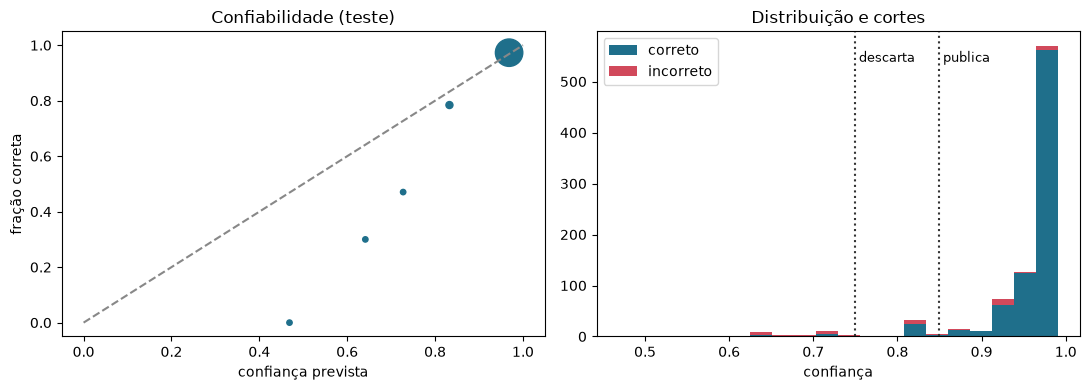

In [16]:
p_oof, y_oof = CAL.fora_da_amostra
X_t, y_t, _ = exemplos([ATIVA[s] for s in TESTE], ROT)
p_t = prob(CAL.pesos, X_t)
curva, ece = confiabilidade(p_t, y_t)
print(f"erro de calibração (ECE) no teste: {ece:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot([0, 1], [0, 1], ls="--", c="#888")
ax[0].scatter([c[0] for c in curva], [c[1] for c in curva], s=[max(15, c[2] / 2) for c in curva], c="#1f6f8b")
ax[0].set(xlabel="confiança prevista", ylabel="fração correta", title="Confiabilidade (teste)")
ax[1].hist([p_t[y_t == 1], p_t[y_t == 0]], bins=20, stacked=True, color=["#1f6f8b", "#d1495b"], label=["correto", "incorreto"])
for x, nome in ((CAL.corte_descartar, "descarta"), (CAL.corte_publicar, "publica")):
    ax[1].axvline(x, c="#333", ls=":")
    ax[1].text(x, ax[1].get_ylim()[1] * 0.9, f" {nome}", fontsize=9)
ax[1].set(xlabel="confiança", title="Distribuição e cortes"); ax[1].legend()
plt.tight_layout(); plt.show()
assert ece <= 0.05

## 7. Trocar de versão: calibrar a candidata e passar no gate

*Afirmação:* Uma versão candidata (outro prompt, modelo ou schema) muda a distribuição dos sinais, então ajusta a própria calibração nas sentenças de calibração antes de ser comparada. A comparação é nas 200 de teste, por *bootstrap* pareado por sentença, como teste de não inferioridade: a candidata só vira ativa se o limite inferior do IC 95% da diferença de F1 for ≥ −3 pontos e o limite superior do IC 95% da diferença de inventados for ≤ +2 pontos.

As margens são do tamanho que o conjunto de teste consegue distinguir. Para saber esse tamanho, a própria versão ativa é rodada de novo (teste A/A): com margens menores, ela mesma seria reprovada. As primeiras linhas abaixo são esse A/A.

In [17]:
CONT_ATIVA = [contagens(ATIVA[s], GABS[s], ROT) for s in TESTE]
perfis = {
    "A/A: a versão ativa de novo (1)": (PerfilSimulado(), 2),
    "A/A: a versão ativa de novo (2)": (PerfilSimulado(), 3),
    "candidata A (esquece menos, distorce menos)": (PerfilSimulado("cand_a", p_esquecido=0.03, p_distorce=0.02, p_parafrase=0.04), 7),
    "candidata B (verificador mais fraco)": (PerfilSimulado("cand_b", p_distorce=0.12, verificador_erro=0.06), 7),
}
GATES = {}
for nome, (perfil, seed) in perfis.items():
    versao, _ = versao_extracao(f"perfil={perfil.nome}")
    ex, _ = rodar(perfil, seed, versao)
    rot = rotular(list(ex.values()), GABS)
    cal = calibrar([ex[s] for s in CALIB], rot, papeis_de_referencia(list(ex.values()), GABS))          # a candidata calibra na própria distribuição de sinais
    aplicar_decisao(list(ex.values()), cal)
    cont = [contagens(ex[s], GABS[s], rot) for s in TESTE]
    m = resumir(cont)
    GATES[nome] = g = gate(CONT_ATIVA, cont)
    print(f"{nome}\n  versão {versao} | F1 {M['f1']:.3f} → {m['f1']:.3f} | inventados {M['inventados']:.2%} → {m['inventados']:.2%}")
    print(f"  IC 95% ΔF1 [{g['ic_dif_f1'][0]:+.3f}, {g['ic_dif_f1'][1]:+.3f}] | IC 95% Δinventados [{g['ic_dif_inventados'][0]:+.3%}, {g['ic_dif_inventados'][1]:+.3%}]"
          f" → {'APROVADA' if g['aprovada'] else 'REPROVADA'}")
assert GATES["A/A: a versão ativa de novo (1)"]["aprovada"] and GATES["A/A: a versão ativa de novo (2)"]["aprovada"]
assert GATES["candidata A (esquece menos, distorce menos)"]["aprovada"]
assert not GATES["candidata B (verificador mais fraco)"]["aprovada"]

A/A: a versão ativa de novo (1)
  versão ext_c28d8ed1f5 | F1 0.864 → 0.874 | inventados 0.76% → 1.26%
  IC 95% ΔF1 [-0.017, +0.037] | IC 95% Δinventados [-0.533%, +1.555%] → APROVADA


A/A: a versão ativa de novo (2)
  versão ext_c28d8ed1f5 | F1 0.864 → 0.866 | inventados 0.76% → 0.51%
  IC 95% ΔF1 [-0.028, +0.031] | IC 95% Δinventados [-1.010%, +0.519%] → APROVADA


candidata A (esquece menos, distorce menos)
  versão ext_97933edc00 | F1 0.864 → 0.897 | inventados 0.76% → 0.36%
  IC 95% ΔF1 [+0.003, +0.061] | IC 95% Δinventados [-1.149%, +0.331%] → APROVADA


candidata B (verificador mais fraco)
  versão ext_8d06cf4f62 | F1 0.864 → 0.776 | inventados 0.76% → 3.26%
  IC 95% ΔF1 [-0.125, -0.053] | IC 95% Δinventados [+1.056%, +3.934%] → REPROVADA


## 8. Recalibrar não reextrai

*Afirmação:* `versao_extracao` cobre prompts, modelos, schema e código; a calibração tem versão própria (`versao_decisao`). Como os sinais ficam gravados com cada argumento, mudar a regressão ou os cortes reaplica a decisão sem nenhuma chamada ao LLM, e a chave de idempotência `(sentença, texto_hash, versao_extracao)` não muda.

In [18]:
import q2
antes = {a["id"]: a["status"] for e in ATIVA.values() for a in e.argumentos}
versao_decisao_antes = CAL.versao
cortes_98 = escolher_cortes(CAL.fora_da_amostra[0], precisao_alvo=0.98)
cal_98 = replace(CAL, corte_publicar=cortes_98[0], corte_descartar=cortes_98[1],
                 versao=sha256(json.dumps([list(np.round(CAL.pesos, 6)), *cortes_98]))[:10])
contador = Contador(LLMSimulado(GABS))
aplicar_decisao(list(ATIVA.values()), cal_98)
mudaram = sum(antes[a["id"]] != a["status"] for e in ATIVA.values() for a in e.argumentos)
print(f"versão de extração {VERSAO_ATIVA} (igual) | decisão {versao_decisao_antes} → {cal_98.versao}")
print(f"corte de publicação {CAL.corte_publicar:.3f} → {cal_98.corte_publicar:.3f}: {mudaram} argumentos mudaram de status, {contador.n} chamadas ao LLM")
assert contador.n == 0 and mudaram > 0 and cal_98.versao != versao_decisao_antes
_ = aplicar_decisao(list(ATIVA.values()), CAL)   # volta à decisão ativa

versão de extração ext_c28d8ed1f5 (igual) | decisão 2e9003e8fb → 35bd6c7ecd
corte de publicação 0.849 → 0.972: 374 argumentos mudaram de status, 0 chamadas ao LLM


## 9. Revisão humana e versionamento

*Afirmação:* A extração é imutável; a revisão é uma tabela de eventos só com inserção, e a base consulta a visão `argumento_atual`. Uma edição é reverificada (referência que não está no trecho gera aviso). Dois revisores não sobrescrevem um ao outro (trava otimista). Numa reextração com outra versão, a linhagem liga o mesmo argumento entre execuções, um para um (algoritmo húngaro: dois argumentos novos nunca herdam a mesma linhagem): aprovado ou editado continua valendo; rejeitado por "não está no texto", "argumento da parte", "duplicado" ou "irrelevante" é suprimido; rejeitado por "resumo distorce" ou "obiter" volta para revisão, porque a nova extração pode ter corrigido; o que o humano adicionou fica.

In [19]:
base = Base()
sid = TESTE[3]
e1 = base.processar(sid, PDFS[sid], LLMSimulado(GABS, seed=11), VERSAO_ATIVA)
aplicar_decisao([e1], CAL)
base.gravar(e1)
args = sorted(base.argumento_atual(sid), key=lambda a: a["trechos"][0]["paragrafo"])
for a in args:
    print(f"{a['id']}  {a['linhagem_id']}  §{a['trechos'][0]['paragrafo']:<3} {a['tipo']:<22} {a['status']:<11} {a['titulo'][:50]}")

arg_6e67dd  lin_f63d36  §13  prejudicial_merito     publicado   Prescrição afastada mesmo pelo prazo da Convenção 
arg_626e17  lin_d5398d  §15  merito_direito         em_revisao  Argumento
arg_b2a1c3  lin_8286d0  §16  merito_direito         publicado   Readequação da malha aérea é fortuito interno
arg_27883a  lin_c3687d  §18  merito_fato            publicado   Gastos comprovados com assistência não prestada
arg_1d7560  lin_b48827  §20  merito_direito         publicado   Atraso sem prova de prejuízo não gera dano moral


In [20]:
publicados = [a for a in args if a["status"] == "publicado"]
a_ok, a_edit, a_dist = publicados[:3]
a_parte = next((a for a in args if a["sinais"]["marcador_alegacao"] or a["sinais"]["postura"] == "relata"), publicados[3])
print(f"rejeitar como argumento da parte: {a_parte['id']} §{a_parte['trechos'][0]['paragrafo']}: {a_parte['trechos'][0]['texto'][:70]}")
print("aceitar:", base.revisar(a_ok["id"], "adv_1", "aceitar", versao_esperada=0))
avisos = base.revisar(a_edit["id"], "adv_1", "editar", versao_esperada=0,
                      campos={"resumo": a_edit["resumo"] + " (revisado)", "precedentes": a_edit["precedentes"] + [{"tribunal": "STJ", "tipo": "resp", "numero": "1"}]})
print("editar com precedente que não está no trecho → avisos:", avisos)
assert avisos
base.revisar(a_dist["id"], "adv_2", "rejeitar", versao_esperada=0, motivo="resumo_distorce")
base.revisar(a_parte["id"], "adv_2", "rejeitar", versao_esperada=0, motivo="argumento_da_parte")
try:
    base.revisar(a_ok["id"], "adv_2", "rejeitar", versao_esperada=0, motivo="irrelevante")   # a tela do adv_2 abriu antes do aceite
except ConflitoDeRevisao as erro:
    print("conflito:", erro)
fund = [p for p in base.sentencas[sid].da_secao("fundamentacao") if not p.titulo]
p_h = fund[-1]
novo = base.adicionar(sid, "adv_1", (p_h.char_ini, p_h.char_ini + 80), titulo="Argumento acrescentado pelo revisor",
                      resumo="O juiz conclui o tópico.", tipo="merito_direito", papel="ratio_decidendi", pedidos=["P1"],
                      conclusao="acolhe", favorece="autor")
print("adicionado:", novo, "| trecho:", json.loads(base.args[novo])["trechos"][0]["texto"][:60])
print("eventos:", [(ev["acao"], ev["motivo"]) for ev in base.eventos])

rejeitar como argumento da parte: arg_626e17 §15: A ré sustenta que o atraso decorreu de readequação da malha aérea, o q
aceitar: []
editar com precedente que não está no trecho → avisos: ["precedente {'tribunal': 'STJ', 'tipo': 'resp', 'numero': '1'} não está escrito no §16"]
conflito: lin_f63d36: outra revisão foi gravada depois que esta tela abriu
adicionado: arg_ha62f7 | trecho: O atraso de voo, por si só, não gera dano moral presumido (S
eventos: [('aceitar', None), ('editar', None), ('rejeitar', 'resumo_distorce'), ('rejeitar', 'argumento_da_parte'), ('adicionar', None)]


In [21]:
versao_nova, _ = versao_extracao("perfil=cand_a")
chamadas_antes = base.chamadas_llm
base.processar(sid, PDFS[sid], LLMSimulado(GABS, seed=11), VERSAO_ATIVA)
print("mesma versão de novo → chamadas ao LLM:", base.chamadas_llm - chamadas_antes, "(idempotente)")
assert base.chamadas_llm == chamadas_antes
e2 = base.processar(sid, PDFS[sid], LLMSimulado(GABS, perfis["candidata A (esquece menos, distorce menos)"][0], seed=12), versao_nova)
aplicar_decisao([e2], CAL)
base.gravar(e2)
print(f"run ativo: {base.ativo[sid]} (versão {versao_nova}); run anterior {e1.run_id} continua consultável: {e1.run_id in base.runs}\n")
atual = {a["linhagem_id"]: a for a in base.argumento_atual(sid)}
for nome, a in (("aceito", a_ok), ("editado", a_edit), ("rejeitado: resumo_distorce", a_dist), ("rejeitado: argumento_da_parte", a_parte)):
    n = atual.get(a["linhagem_id"])
    print(f"{nome:<30} → {n['status'] if n else '(não reapareceu na nova extração)':<12} {n.get('rejeicao_anterior', '') if n else ''}")
assert atual[a_ok["linhagem_id"]]["status"] == "aprovado"
assert atual[a_edit["linhagem_id"]]["status"] == "editado" and atual[a_edit["linhagem_id"]]["resumo"].endswith("(revisado)")
if a_dist["linhagem_id"] in atual:
    assert atual[a_dist["linhagem_id"]]["status"] == "em_revisao"
if a_parte["linhagem_id"] in atual:
    assert atual[a_parte["linhagem_id"]]["status"] == "suprimido"
assert any(a.get("origem") == "humano" for a in atual.values())
linhagens_e2 = [json.loads(base.args[i])["linhagem_id"] for i in base.runs[base.ativo[sid]]["args"]]
assert len(linhagens_e2) == len(set(linhagens_e2)), "cada linhagem tem no máximo um argumento por execução"

mesma versão de novo → chamadas ao LLM: 0 (idempotente)
run ativo: run_067d8deb (versão ext_97933edc00); run anterior run_3cbc8e6d continua consultável: True

aceito                         → aprovado     
editado                        → editado      
rejeitado: resumo_distorce     → em_revisao   resumo_distorce
rejeitado: argumento_da_parte  → suprimido    


## 10. Custo por sentença

*Afirmação:* Por sentença: 1 chamada de mapa (Haiku), uma de extração por tópico (Sonnet, prefixo em cache, mais as reextrações e as dirigidas) e uma de verificação por argumento (Haiku). O custo é tokens × preço vigente de cada modelo; o preço não fica escrito no código.

In [22]:
custo = custo_por_sentenca(list(ATIVA.values()))
print(f"média em {len(ATIVA)} sentenças")
print(f"{'papel':<12}{'chamadas':>9}{'entrada':>9}{'cache escr.':>12}{'cache leit.':>12}{'saída':>8}")
for papel, t in custo.items():
    print(f"{papel:<12}{t['chamadas']:>9}{t['entrada']:>9}{t['cache_escrita']:>12}{t['cache_leitura']:>12}{t['saida']:>8}")
extr = custo["extrator"]
print(f"\nno extrator, {extr['cache_leitura'] / (extr['entrada'] + extr['cache_escrita'] + extr['cache_leitura']):.0%} dos tokens de entrada são leitura de cache")

média em 300 sentenças
papel        chamadas  entrada cache escr. cache leit.   saída
mapa              1.0   1549.7         0.0         0.0   281.2
extrator          3.6    583.1      1318.9      3700.5  1052.7
verificador       5.2   2943.9         0.0         0.0   136.3

no extrator, 66% dos tokens de entrada são leitura de cache
